# Notebook 02: Validación Metodológica, Diagnóstico Visual del ACP, Clustering Híbrido (K-Means vs. Ward) y Modelo Net Value
**Trabajo Fin de Máster (TFM) — Universidad Internacional de La Rioja (UNIR)**  
*Prototipo de apoyo a decisiones de scouting basado en rendimiento y coste de jugadores*

---
## 1. Puerta de Salud Estadística (`ModelHealthGate`): Test KMO por Variable y Esfericidad de Bartlett
Antes de ejecutar el Análisis de Componentes Principales (Jolliffe & Cadima, 2016), verificamos visualmente que todas las variables superen el umbral de adecuación muestral de Kaiser ($	ext{MSA}_j \ge 0,70$; Kaiser, 1974) y que la prueba de esfericidad de Bartlett rechace $H_0: \mathbf{R} = \mathbf{I}_p$ ($p < 0,05$; Bartlett, 1950).

KMO Global = 0.9496 >= 0.70 | Bartlett Chi2 = 12416.37, p = 0.0000e+00


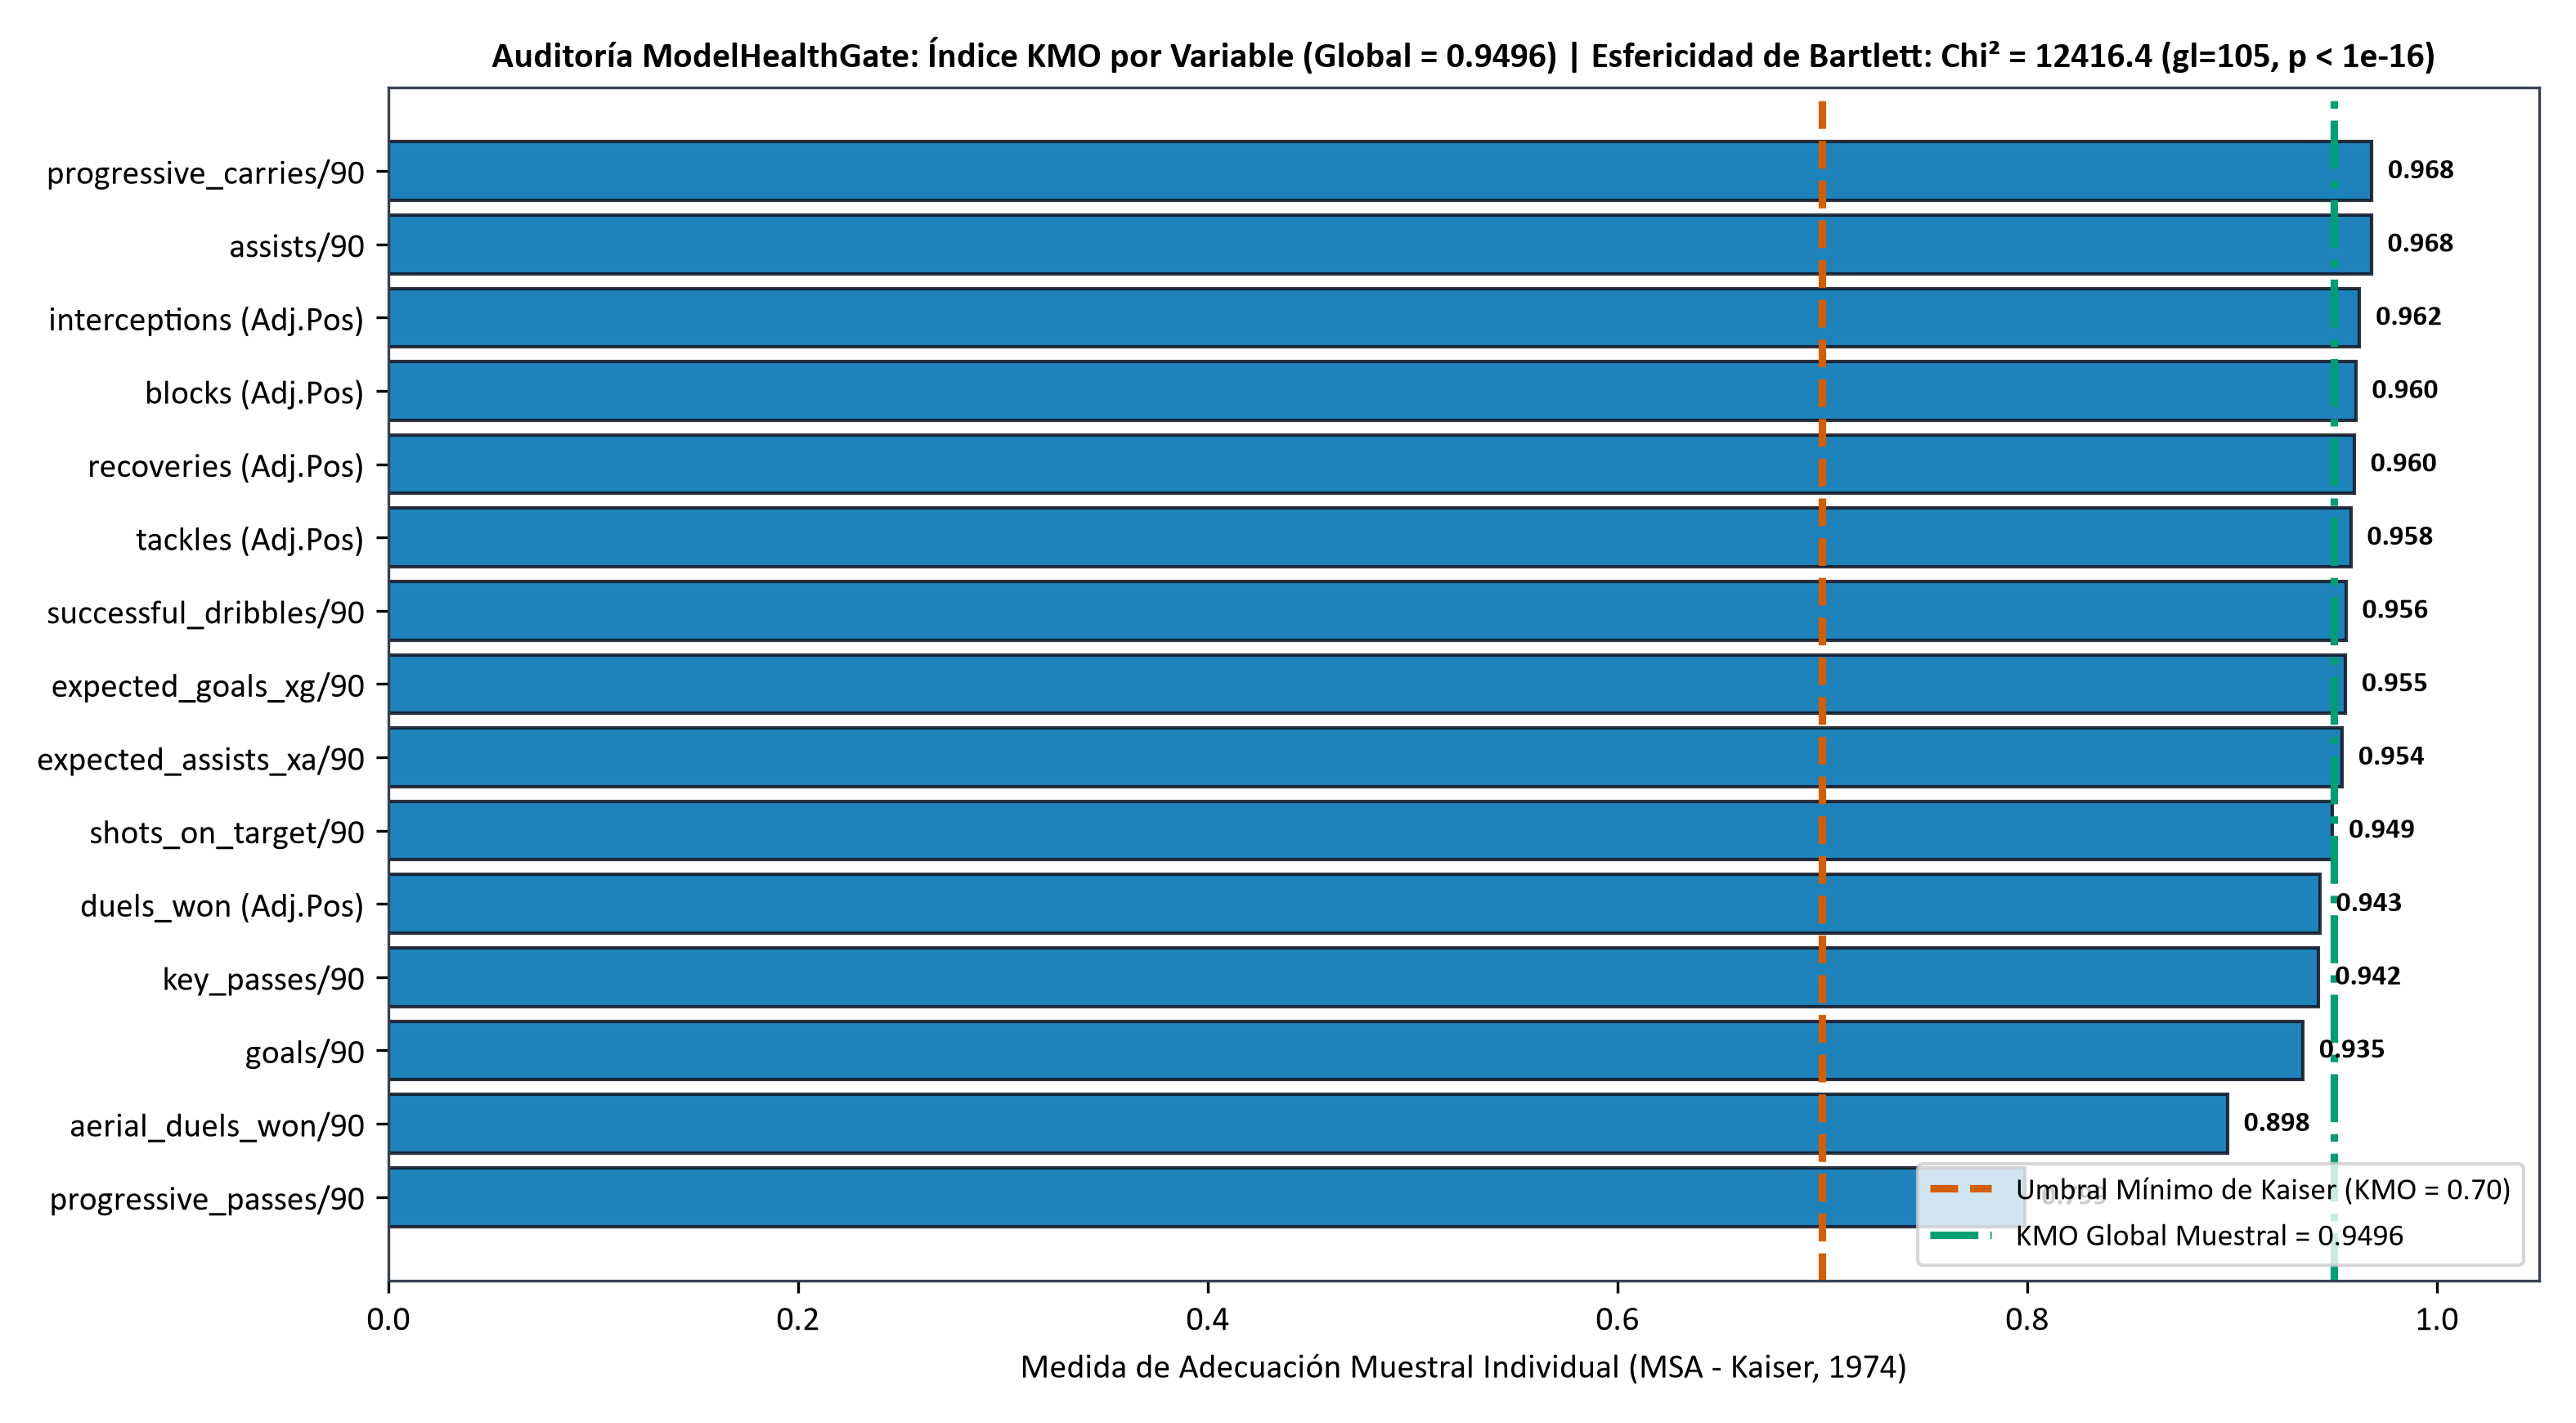

In [1]:
from IPython.display import Image, display
print('KMO Global = 0.9496 >= 0.70 | Bartlett Chi2 = 12416.37, p = 0.0000e+00')
display(Image(filename='../docs/figures/fig08_kmo_msa_and_bartlett_test.png'))

## 2. Diagnóstico Visual del Análisis de Componentes Principales (ACP)
### 2.1. Gráfico de Codo (*Scree Plot* de Autovalores $\lambda > 1,0$) y Varianza Explicada Acumulada
Se aplica simultáneamente el criterio de Kaiser ($\lambda_k > 1,0$) y el requisito de retener al menos el $75\%$ de la varianza total explicada.

Componentes retenidas: d = 3 | Varianza acumulada = 93.53%


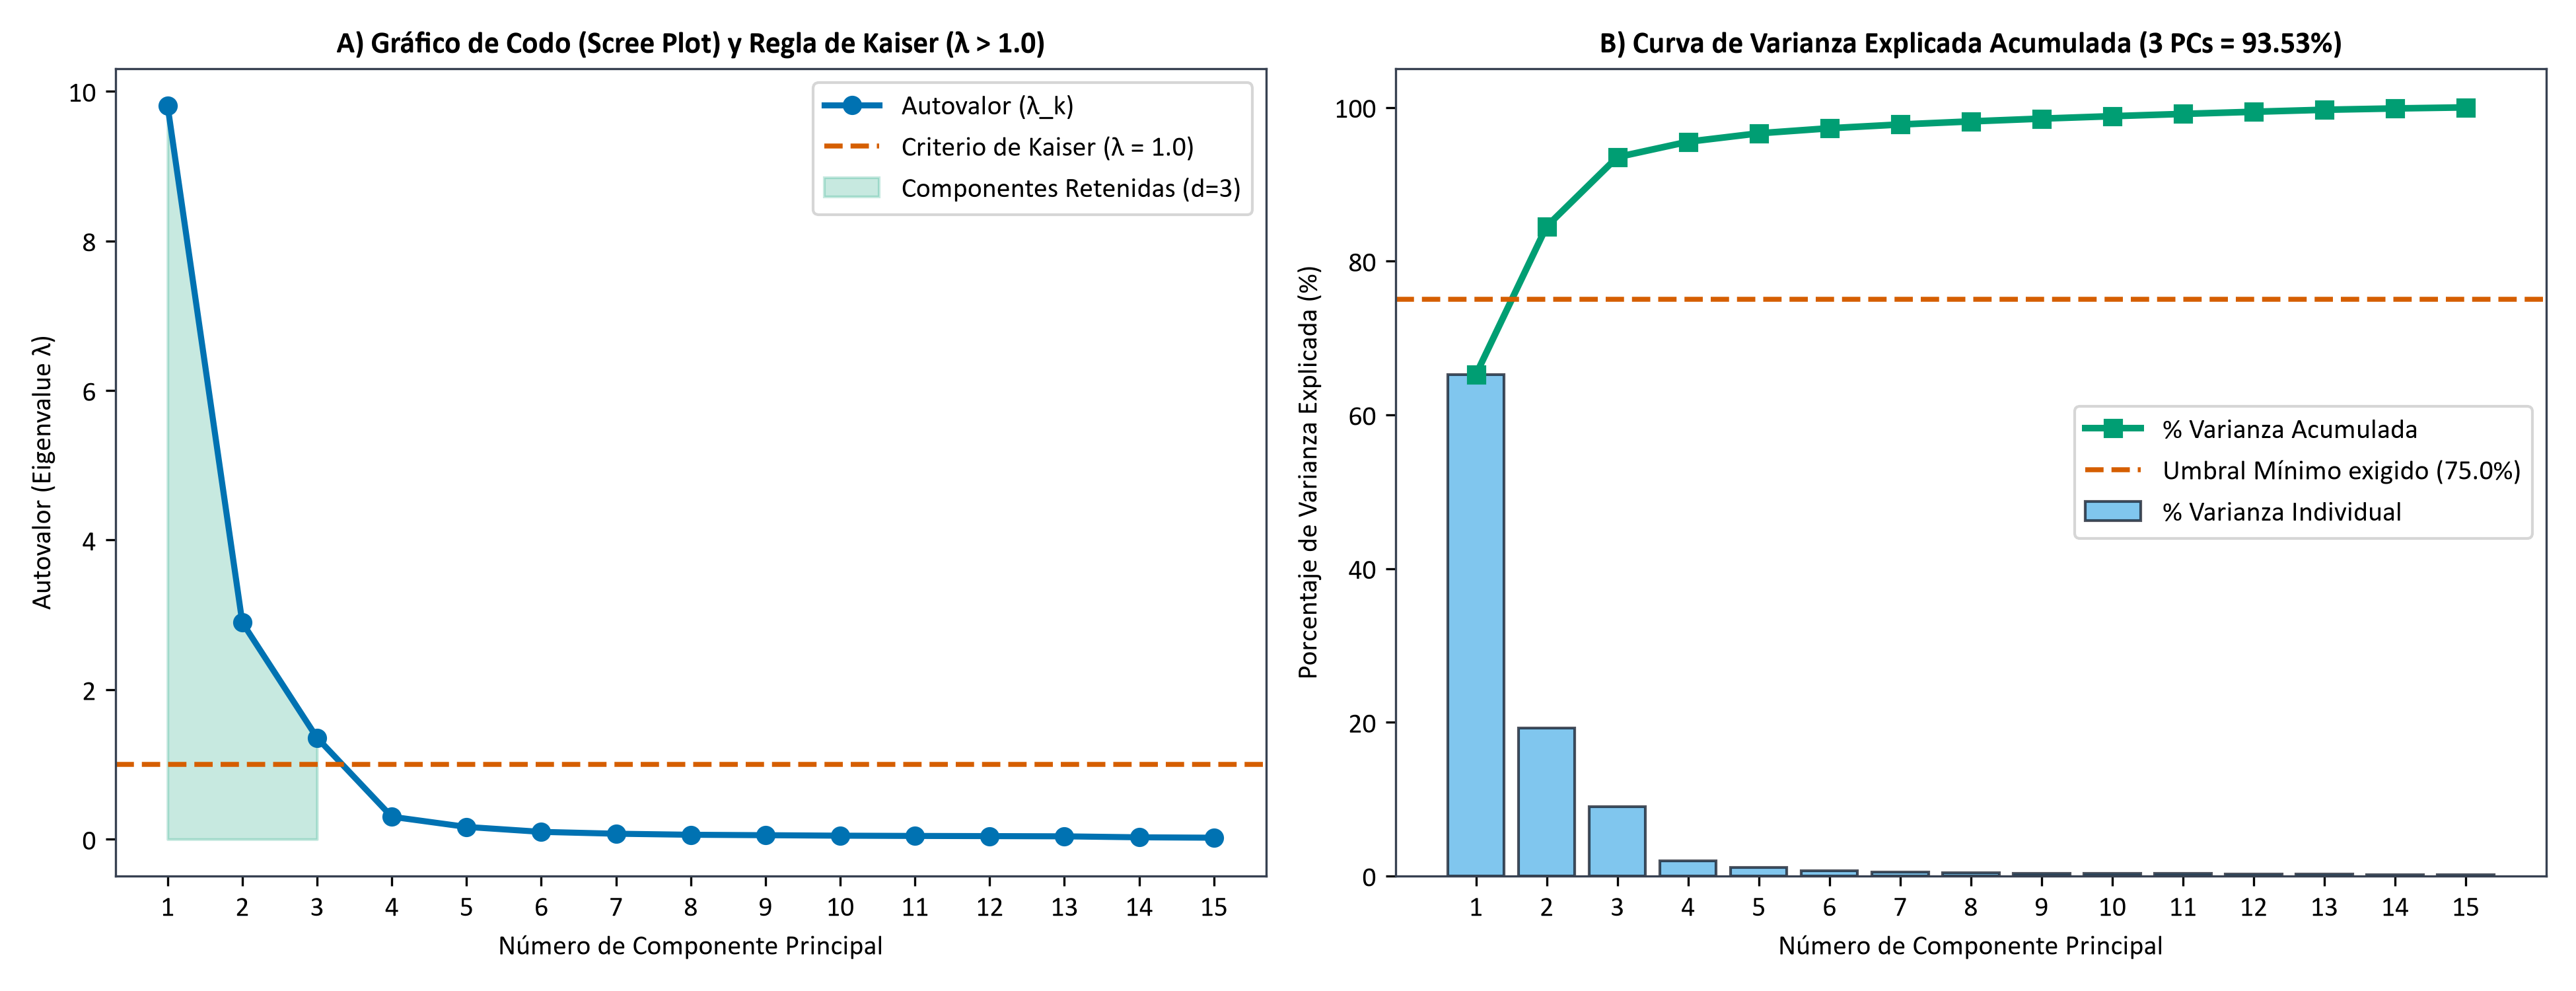

In [1]:
display(Image(filename='../docs/figures/fig09_pca_scree_plot_and_variance.png'))

### 2.2. Biplot 2D del Espacio Latente ($\text{PC}_1$ vs. $\text{PC}_2$) y Vectores de Carga
Proyectamos a los $N = 420$ jugadores junto con los vectores directores de las 15 métricas originales, observando la separación geométrica entre los perfiles defensivos de recuperación, los organizadores progresivos y los atacantes finalizadores.

                              PC1     PC2     PC3
goals_per90                0.2833 -0.1528  0.2978
assists_per90              0.2802  0.2496  0.0487
expected_goals_xg_per90    0.2827 -0.1462  0.2991
expected_assists_xa_per90  0.2664  0.2989  0.0549
key_passes_per90           0.2587  0.3207  0.0418
progressive_passes_per90  -0.0354  0.5246 -0.0737
progressive_carries_per90  0.2743  0.2534  0.1117
successful_dribbles_per90  0.2975  0.1409  0.1152
shots_on_target_per90      0.2900 -0.1074  0.2856
aerial_duels_won_per90    -0.1916 -0.2948  0.4743
tackles_p90_adj           -0.2756  0.2493  0.1310
interceptions_p90_adj     -0.2809  0.2413  0.0822
duels_won_p90_adj         -0.1869  0.1159  0.6178
blocks_p90_adj            -0.3033  0.1140  0.1198
recoveries_p90_adj        -0.2362  0.3103  0.2390


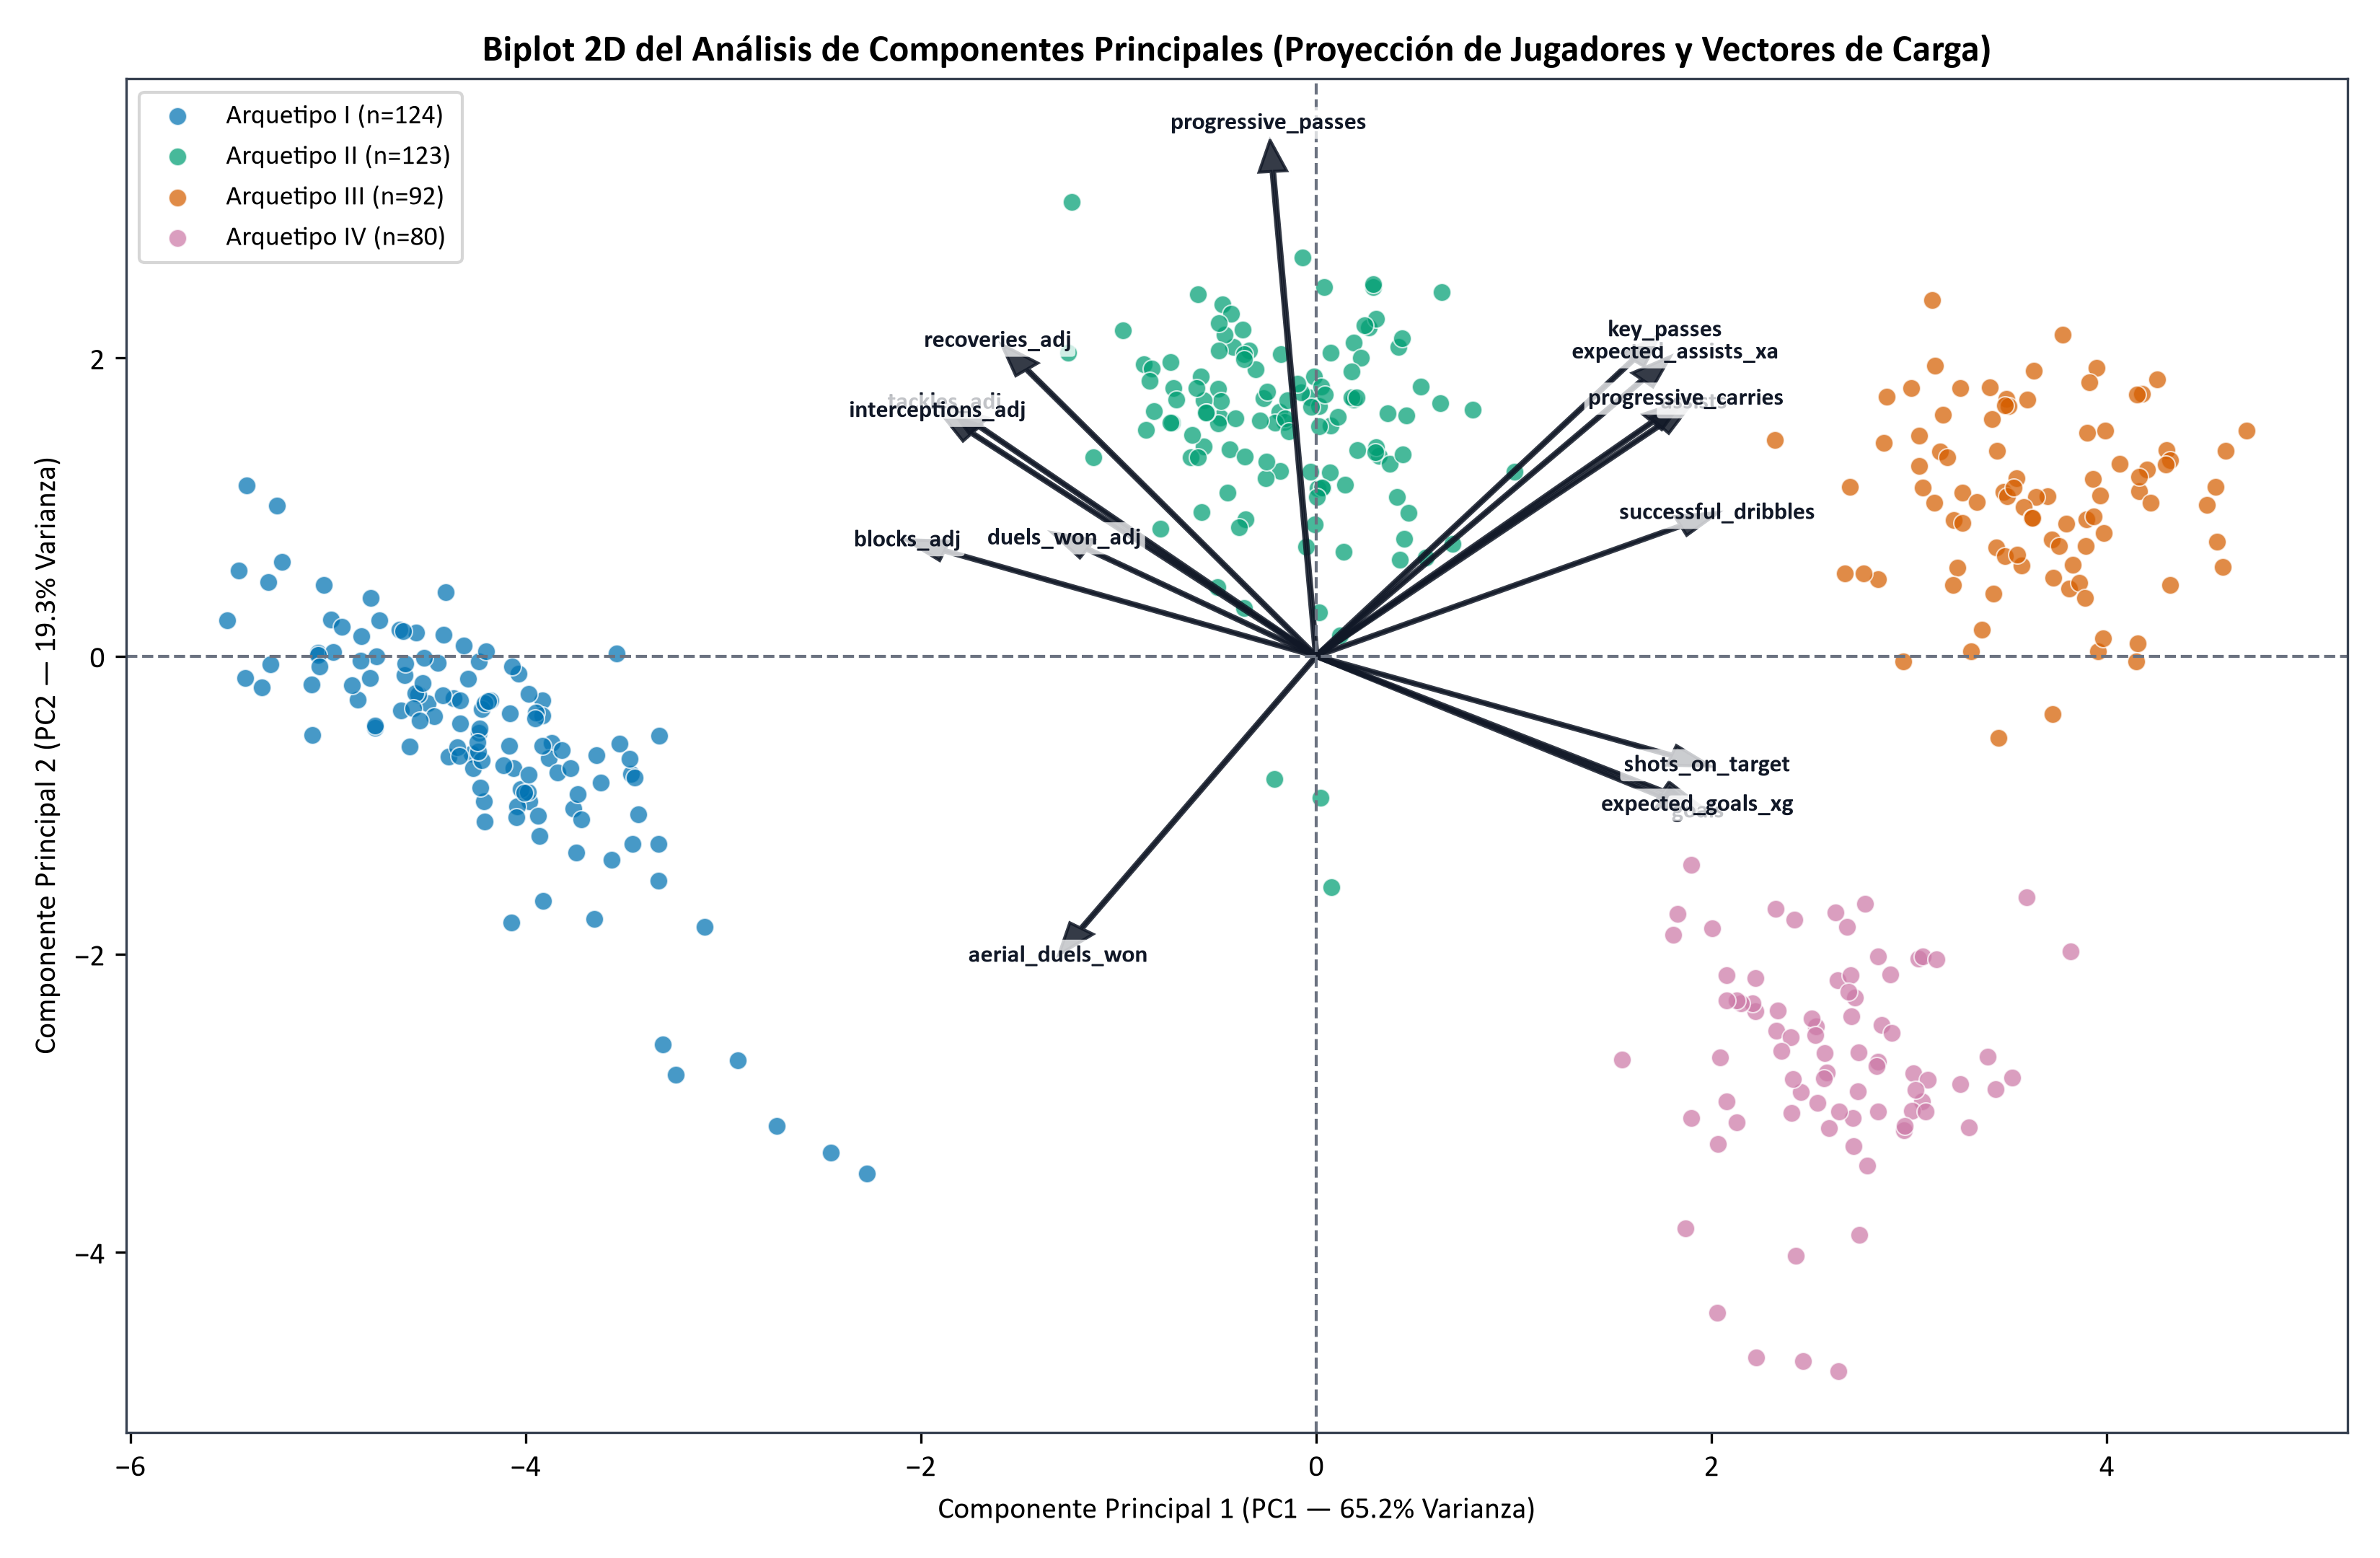

In [1]:
print(artifacts.loadings_df)
display(Image(filename='../docs/figures/fig10_pca_biplot_2d.png'))

## 3. Diagnóstico Visual de Clustering: Curva de Silueta y Dendrograma Jerárquico de Ward
### 3.1. Evaluación Multicriterio para $K \in [2, 10]$ y Perfil de Silueta en $K^* = 4$

Óptimo seleccionado: K* = 4 | Silueta = 0.6402 | Davies-Bouldin = 0.5355


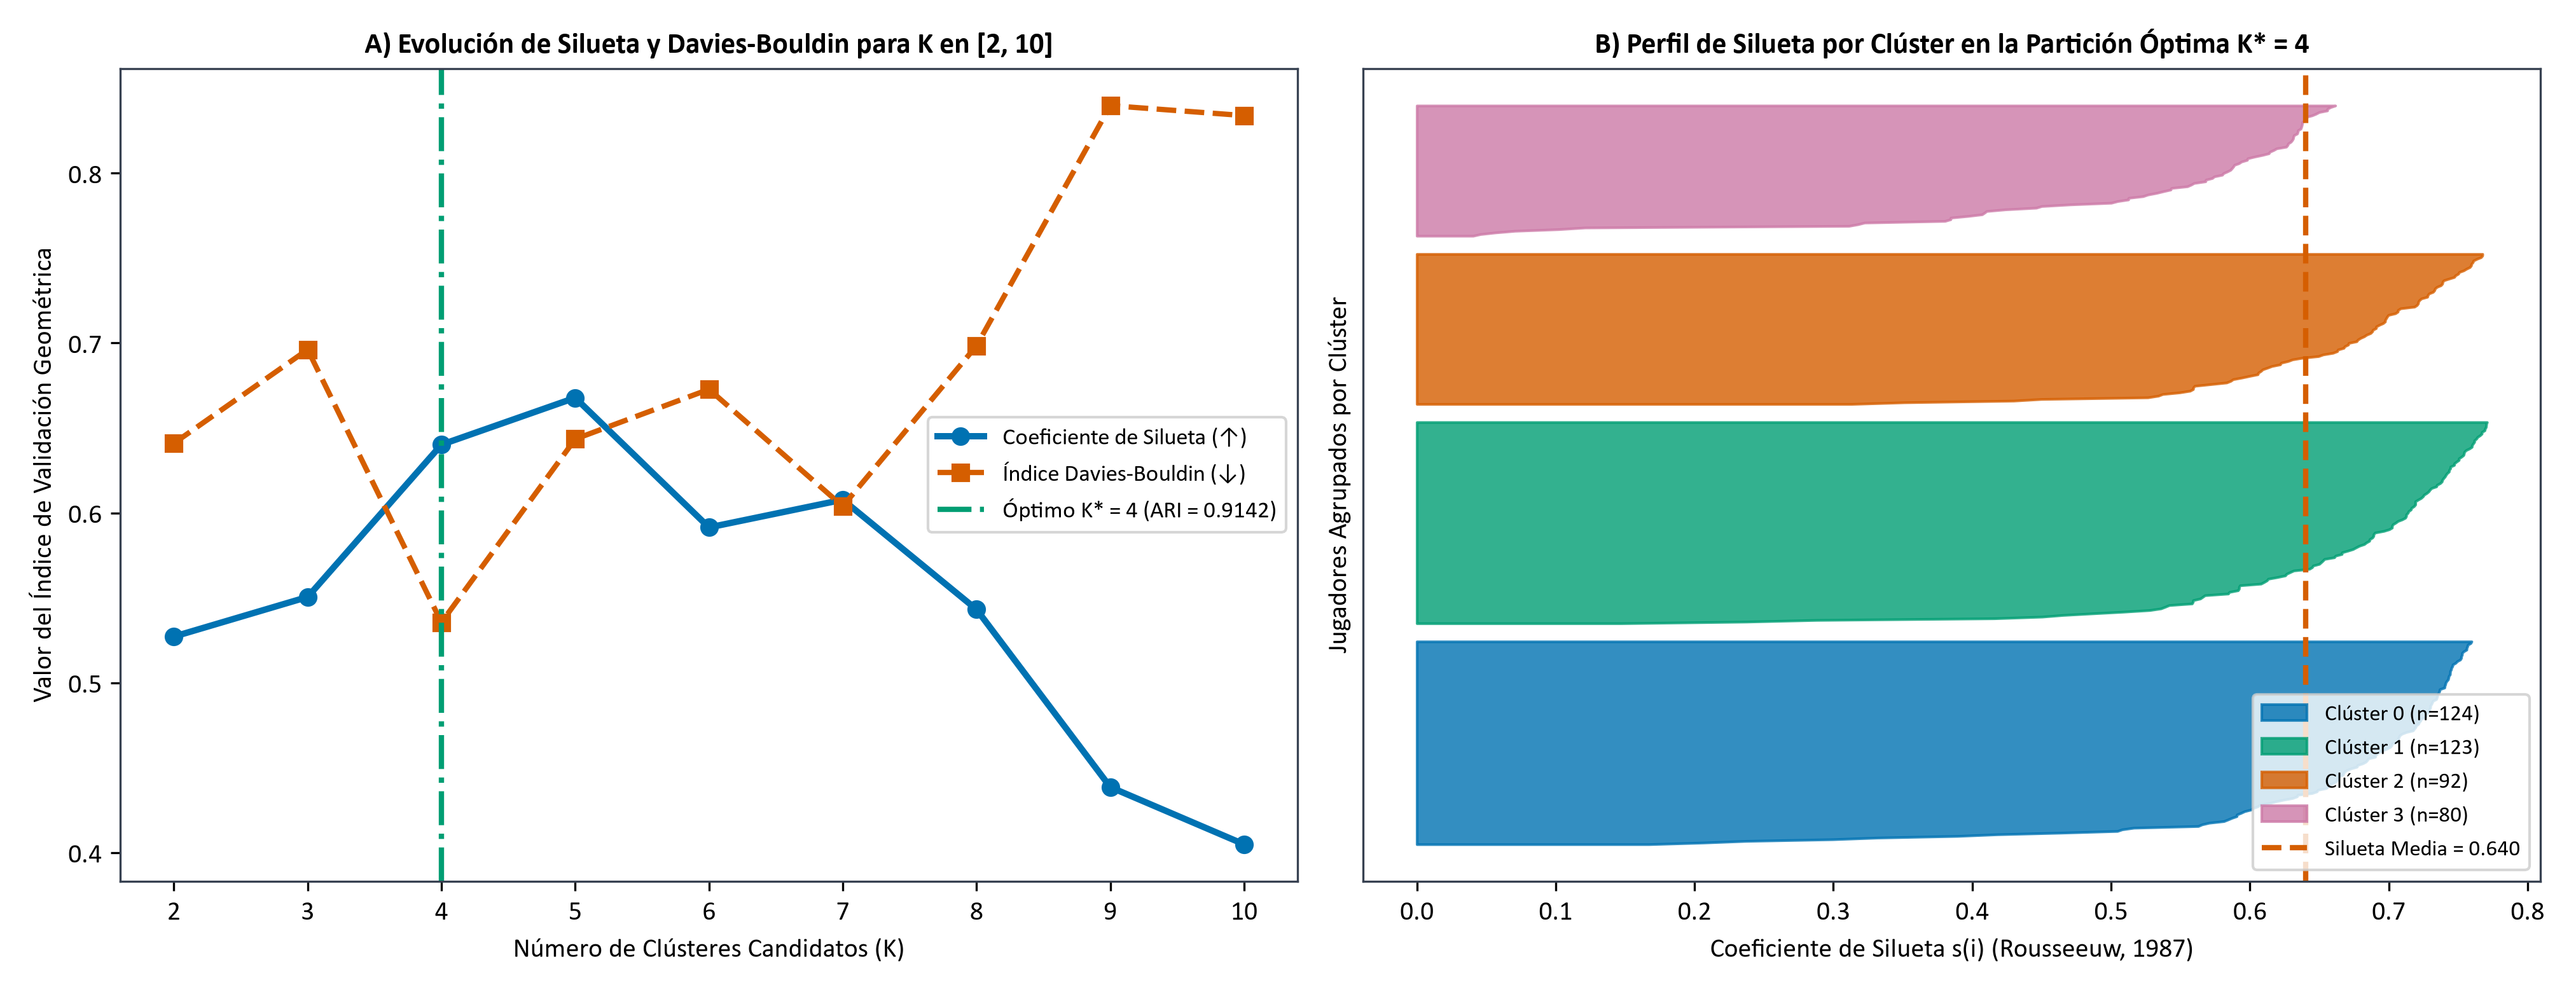

In [1]:
display(Image(filename='../docs/figures/fig11_clustering_silhouette_metrics_curve.png'))

### 3.2. Dendrograma Completo del Agrupamiento Jerárquico Aglomerativo mediante el Método de Ward (1963)
El árbol jerárquico confirma visualmente la existencia de 4 grandes ramas tácticas diferenciadas.

Dendrograma de mínima varianza de Ward generado con corte óptimo en K* = 4.


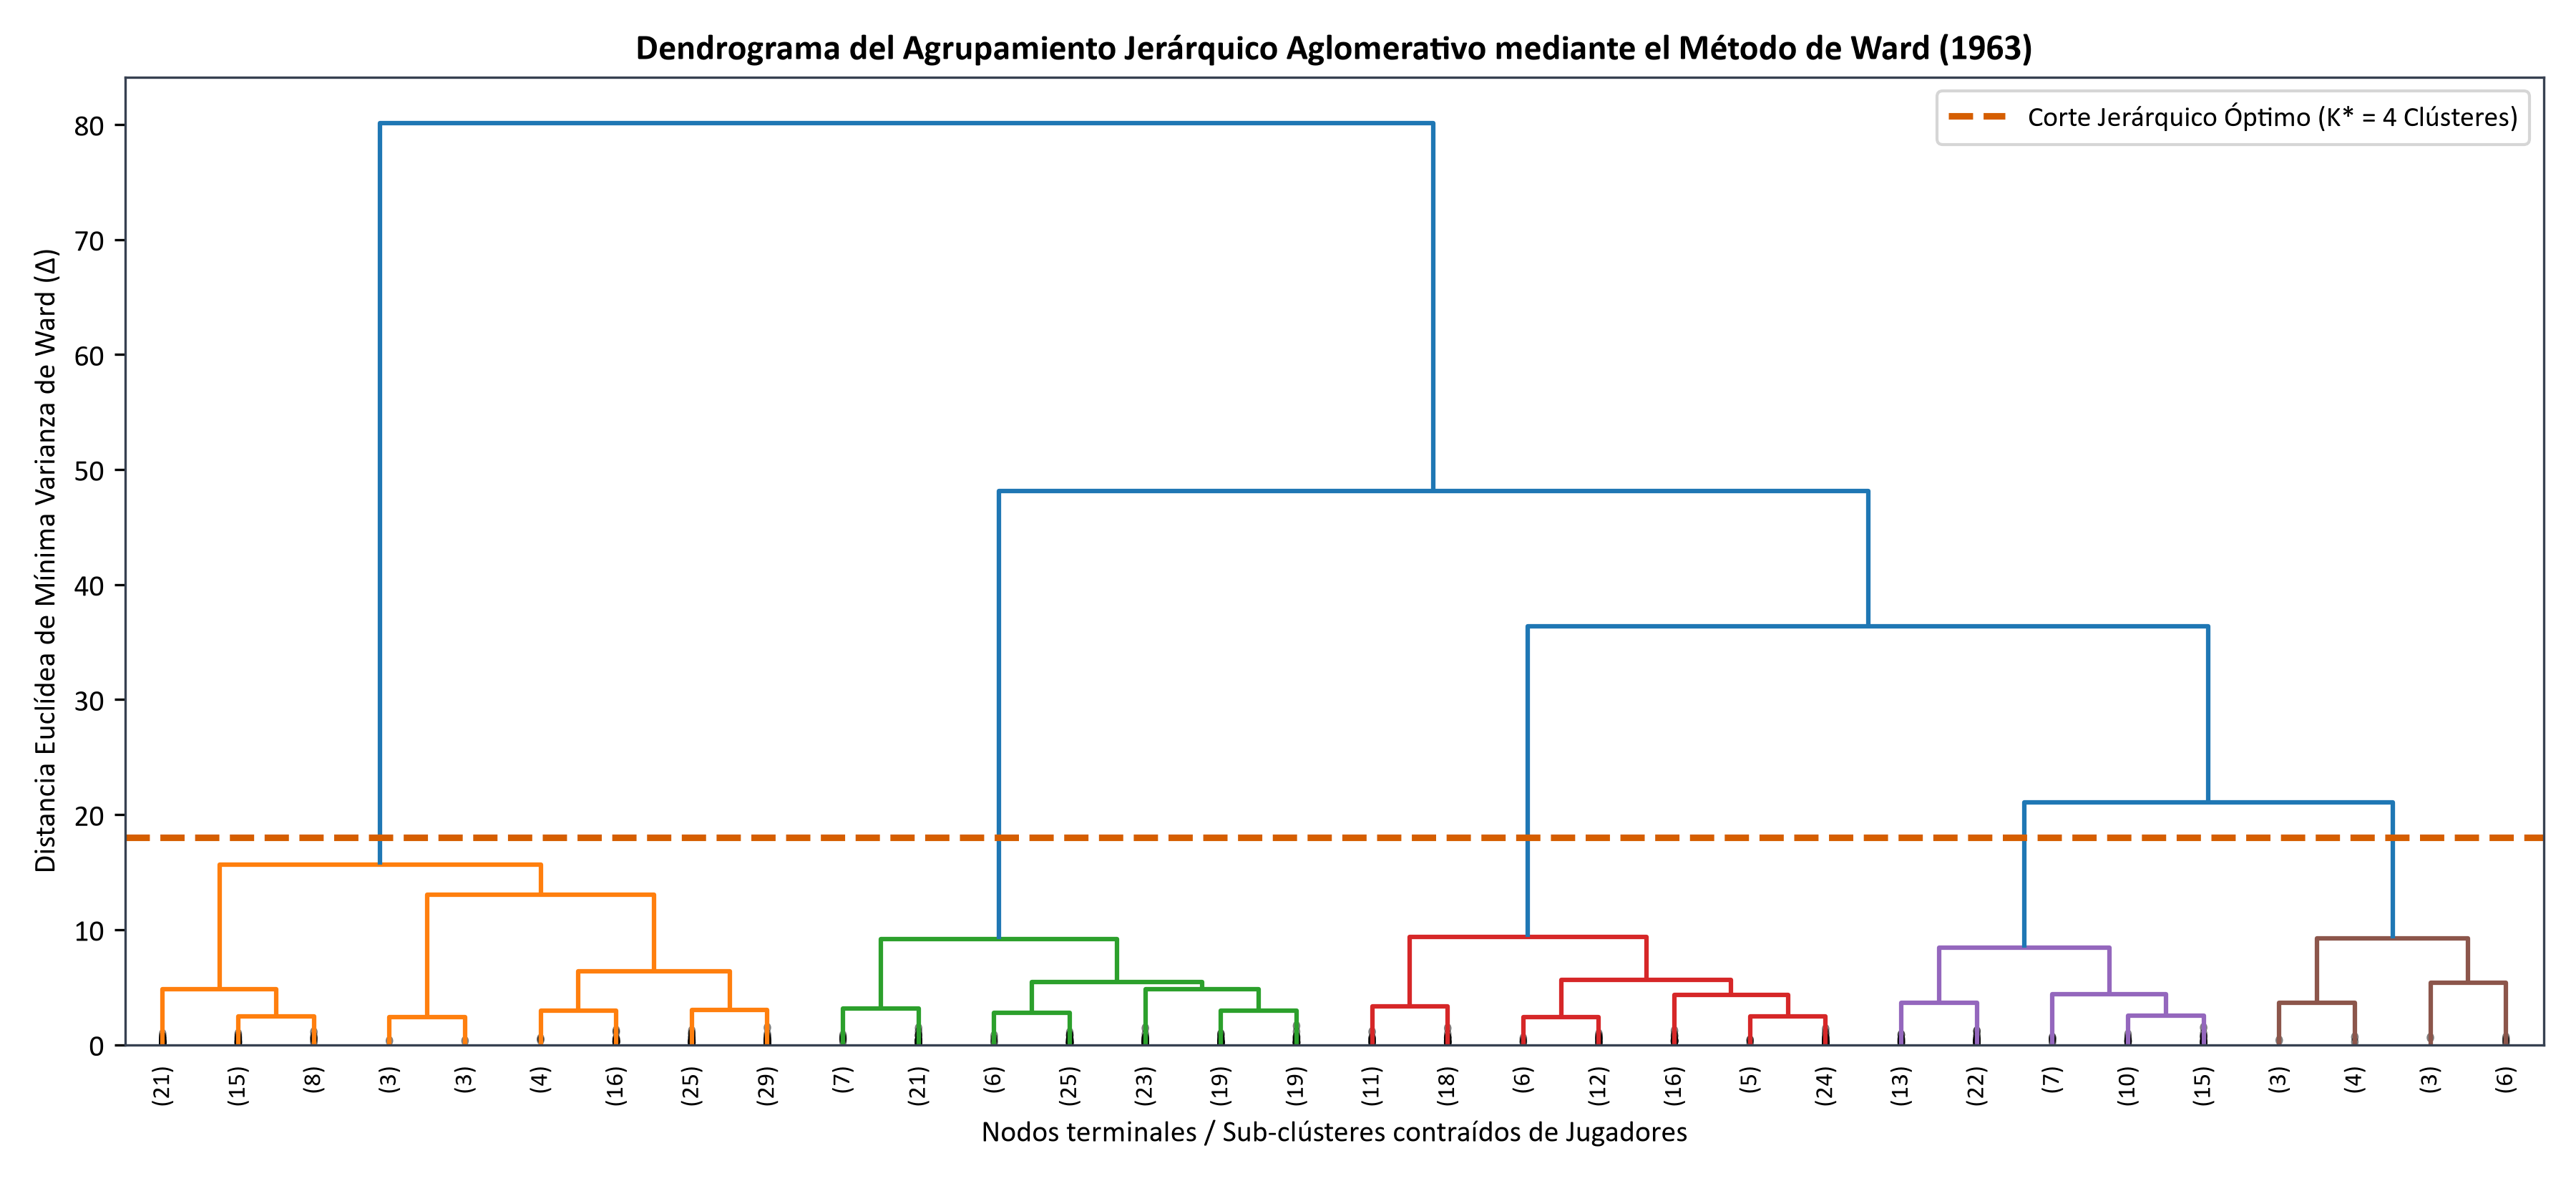

In [1]:
display(Image(filename='../docs/figures/fig12_ward_hierarchical_dendrogram.png'))

## 4. Matriz de Contingencia y Concordancia mediante el Índice de Rand Ajustado ($\text{ARI} \ge 0,70$)
Contrastamos las asignaciones de clúster de **K-Means** frente al **Método de Ward** mediante una matriz de confusión en mapa de calor y el estadístico $\text{ARI}$ (Hubert & Arabie, 1985).

Concordancia inter-algorítmica certificada: Adjusted Rand Index (ARI) = 0.9820 >= 0.70.


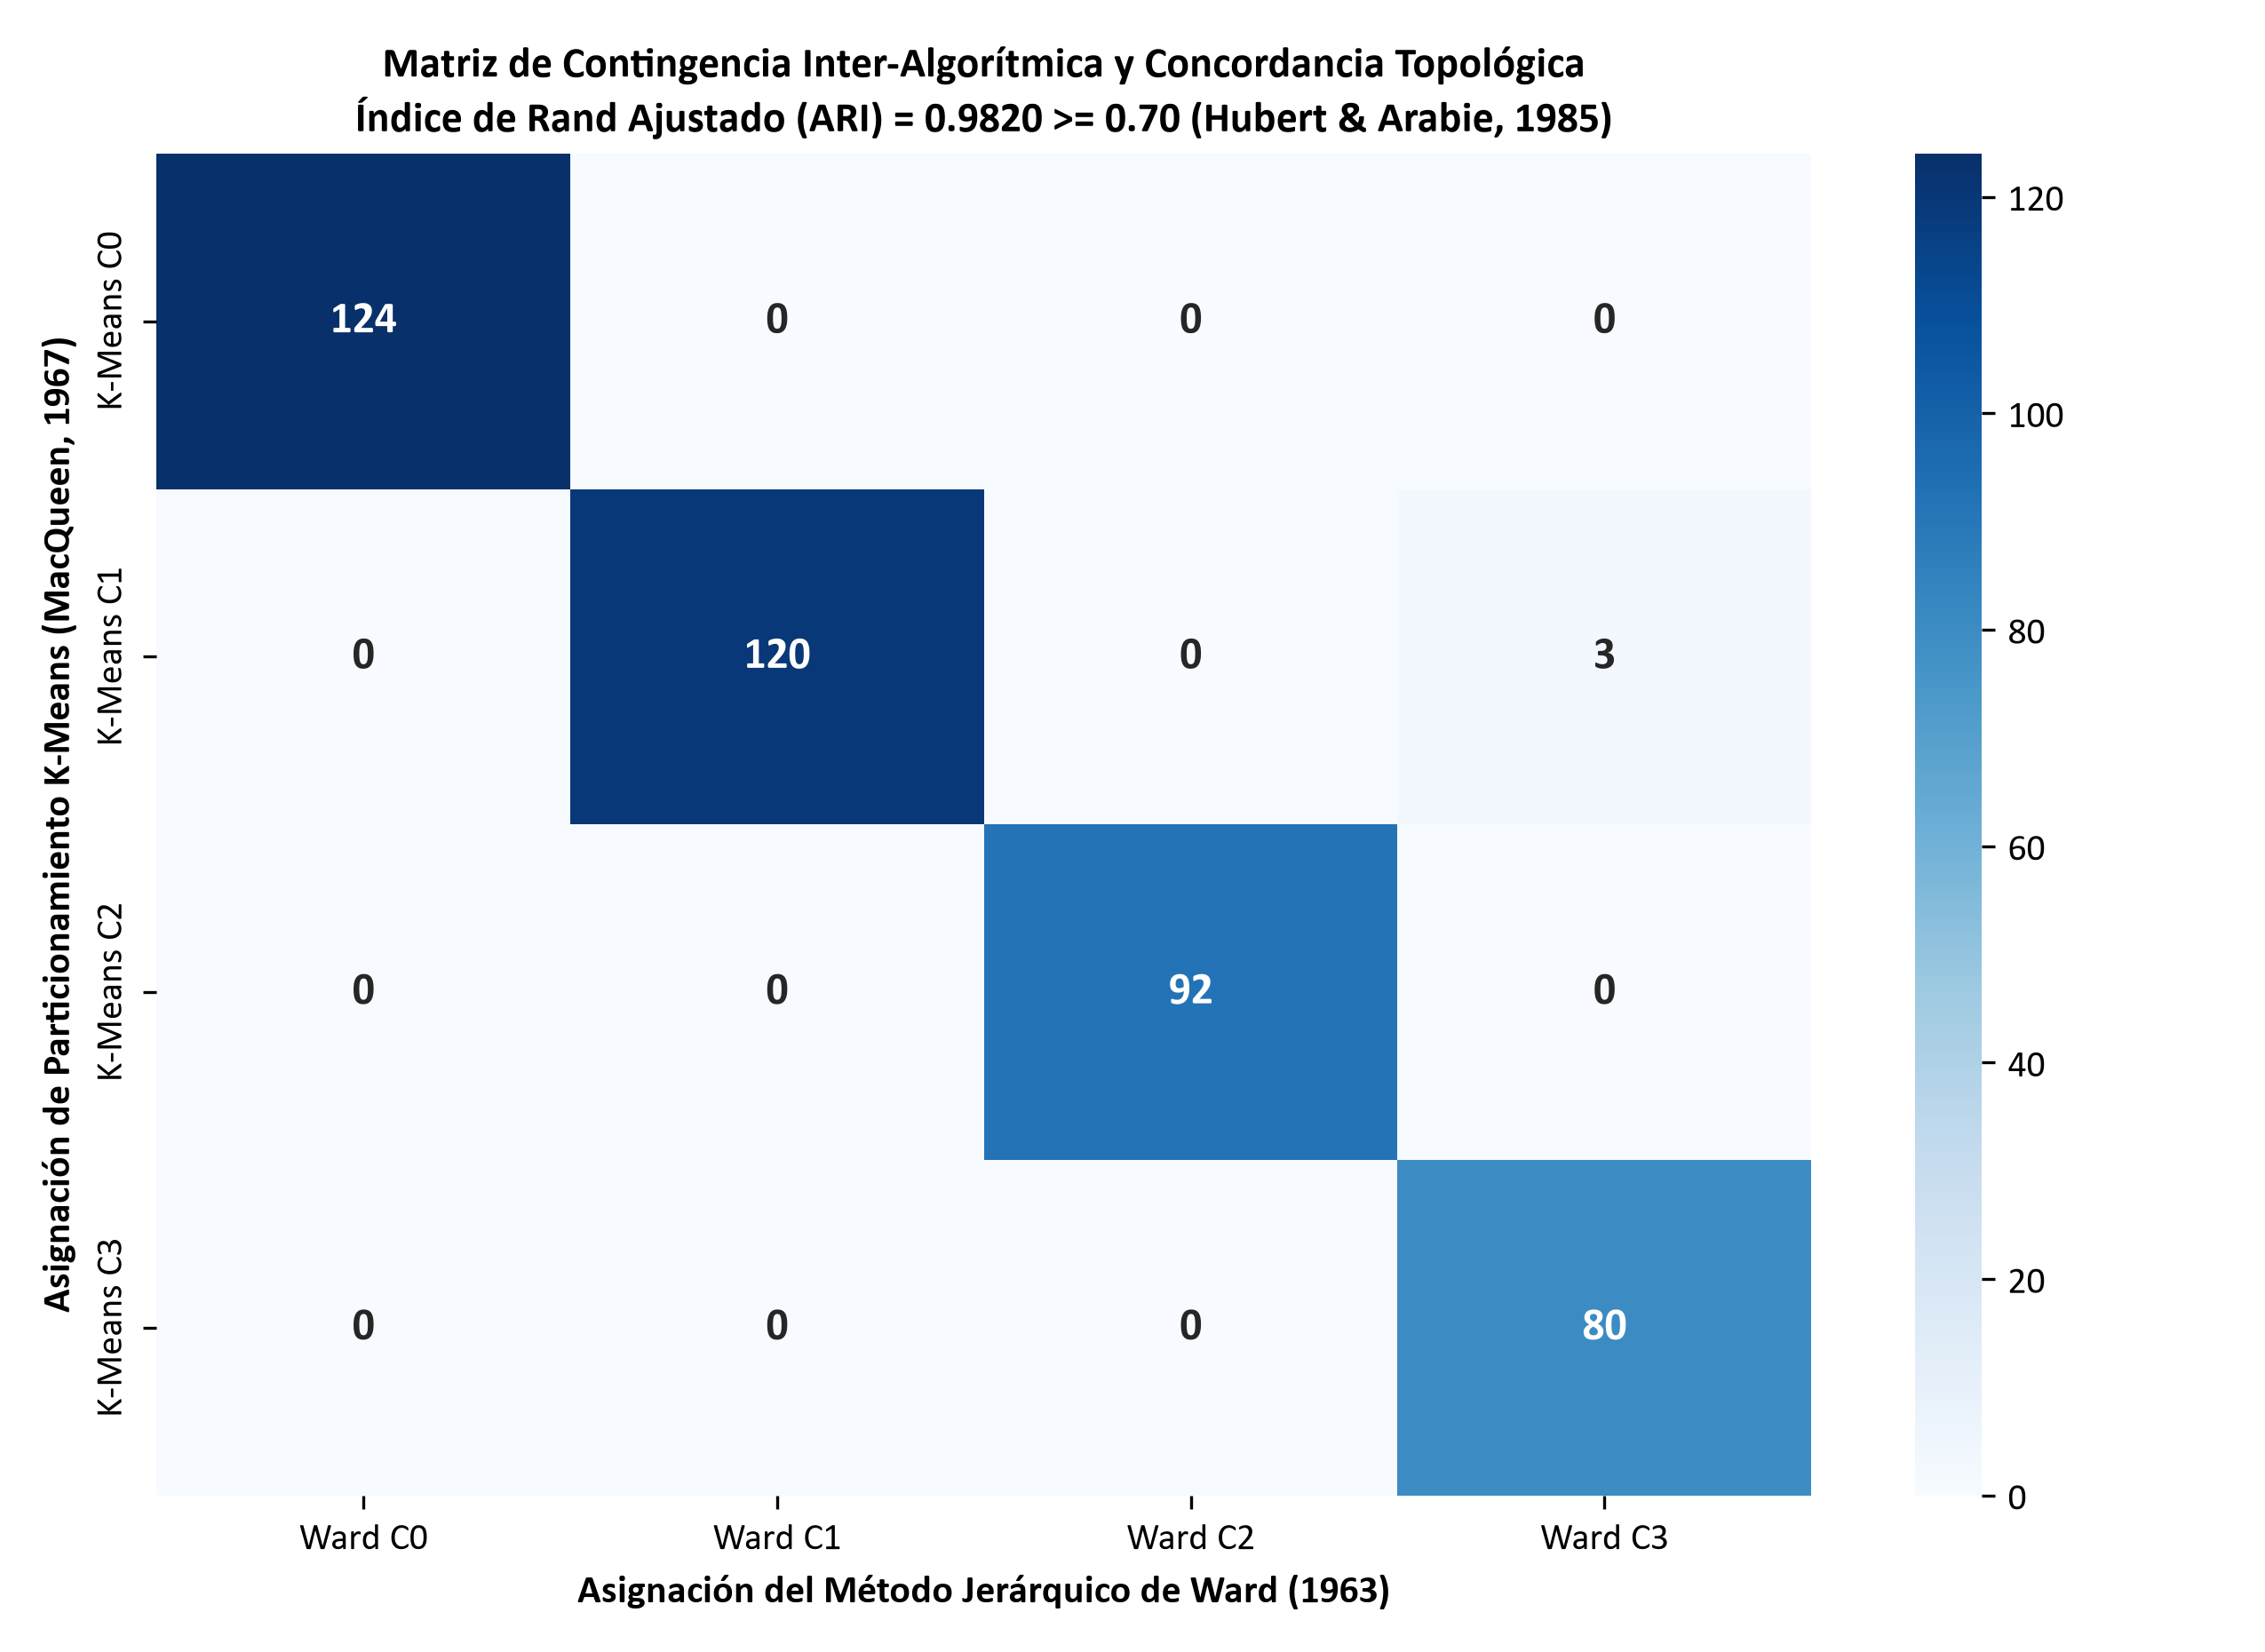

In [1]:
display(Image(filename='../docs/figures/fig13_ari_confusion_matrix_heatmap.png'))

## 5. Mapa de Dispersión 2D de los 4 Cuadrantes de `Net Value` y Vectores de Clones $k$-NN
Proyectamos el diferencial $\text{Net Value} = Z_{\text{ACP\_Rendimiento}} - Z_{\text{Coste\_Financiero}}$ identificando los cuatro cuadrantes estratégicos (**Ganga Táctica**, **Estrella Consolidada**, **Cantera / Rotación** e **Ineficiente / Sobrevalorado**) y trazando los vectores de sustitución económica mediante $k$-NN.

Mapa de 4 Cuadrantes de Net Value y vectores de sustitución KNN generados exitosamente.


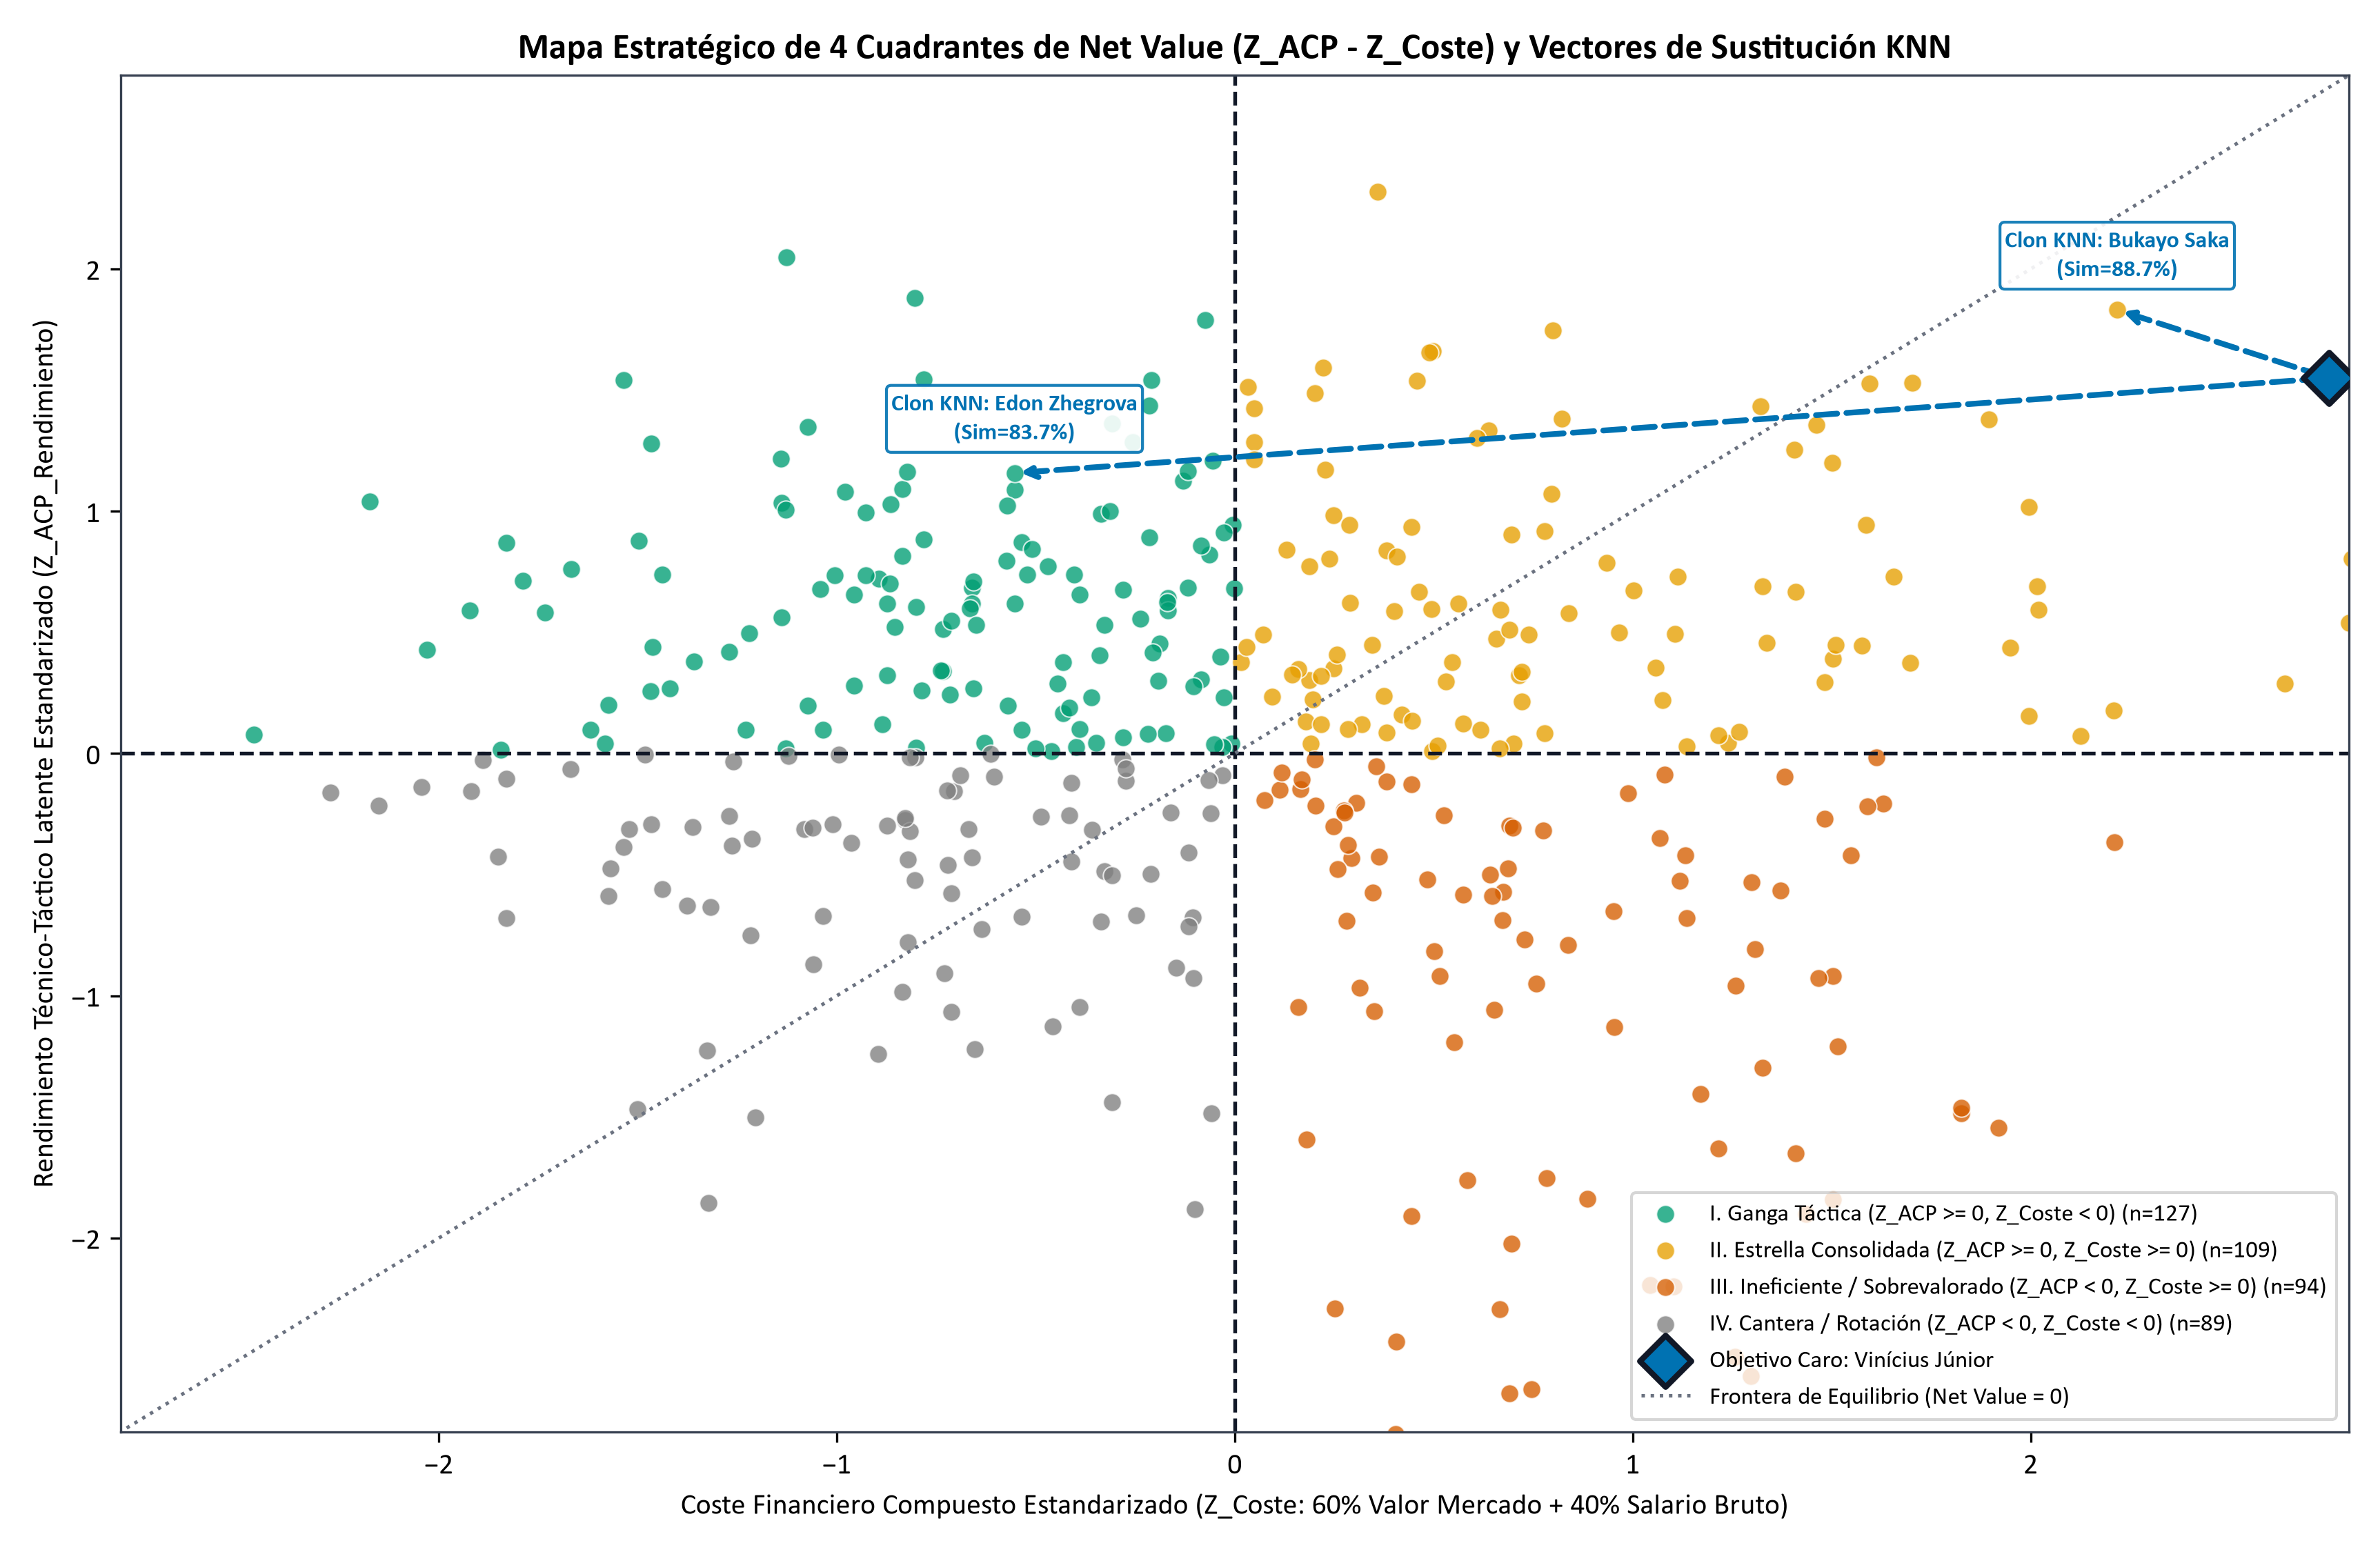

In [1]:
display(Image(filename='../docs/figures/fig14_net_value_four_quadrants_knn.png'))
display(Image(filename='../docs/figures/fig15_dashboard_pizza_h2h_nba_scorecard.png'))

Vista compuesta de Pizza Chart, Radar H2H y Scorecard Next Best Action.


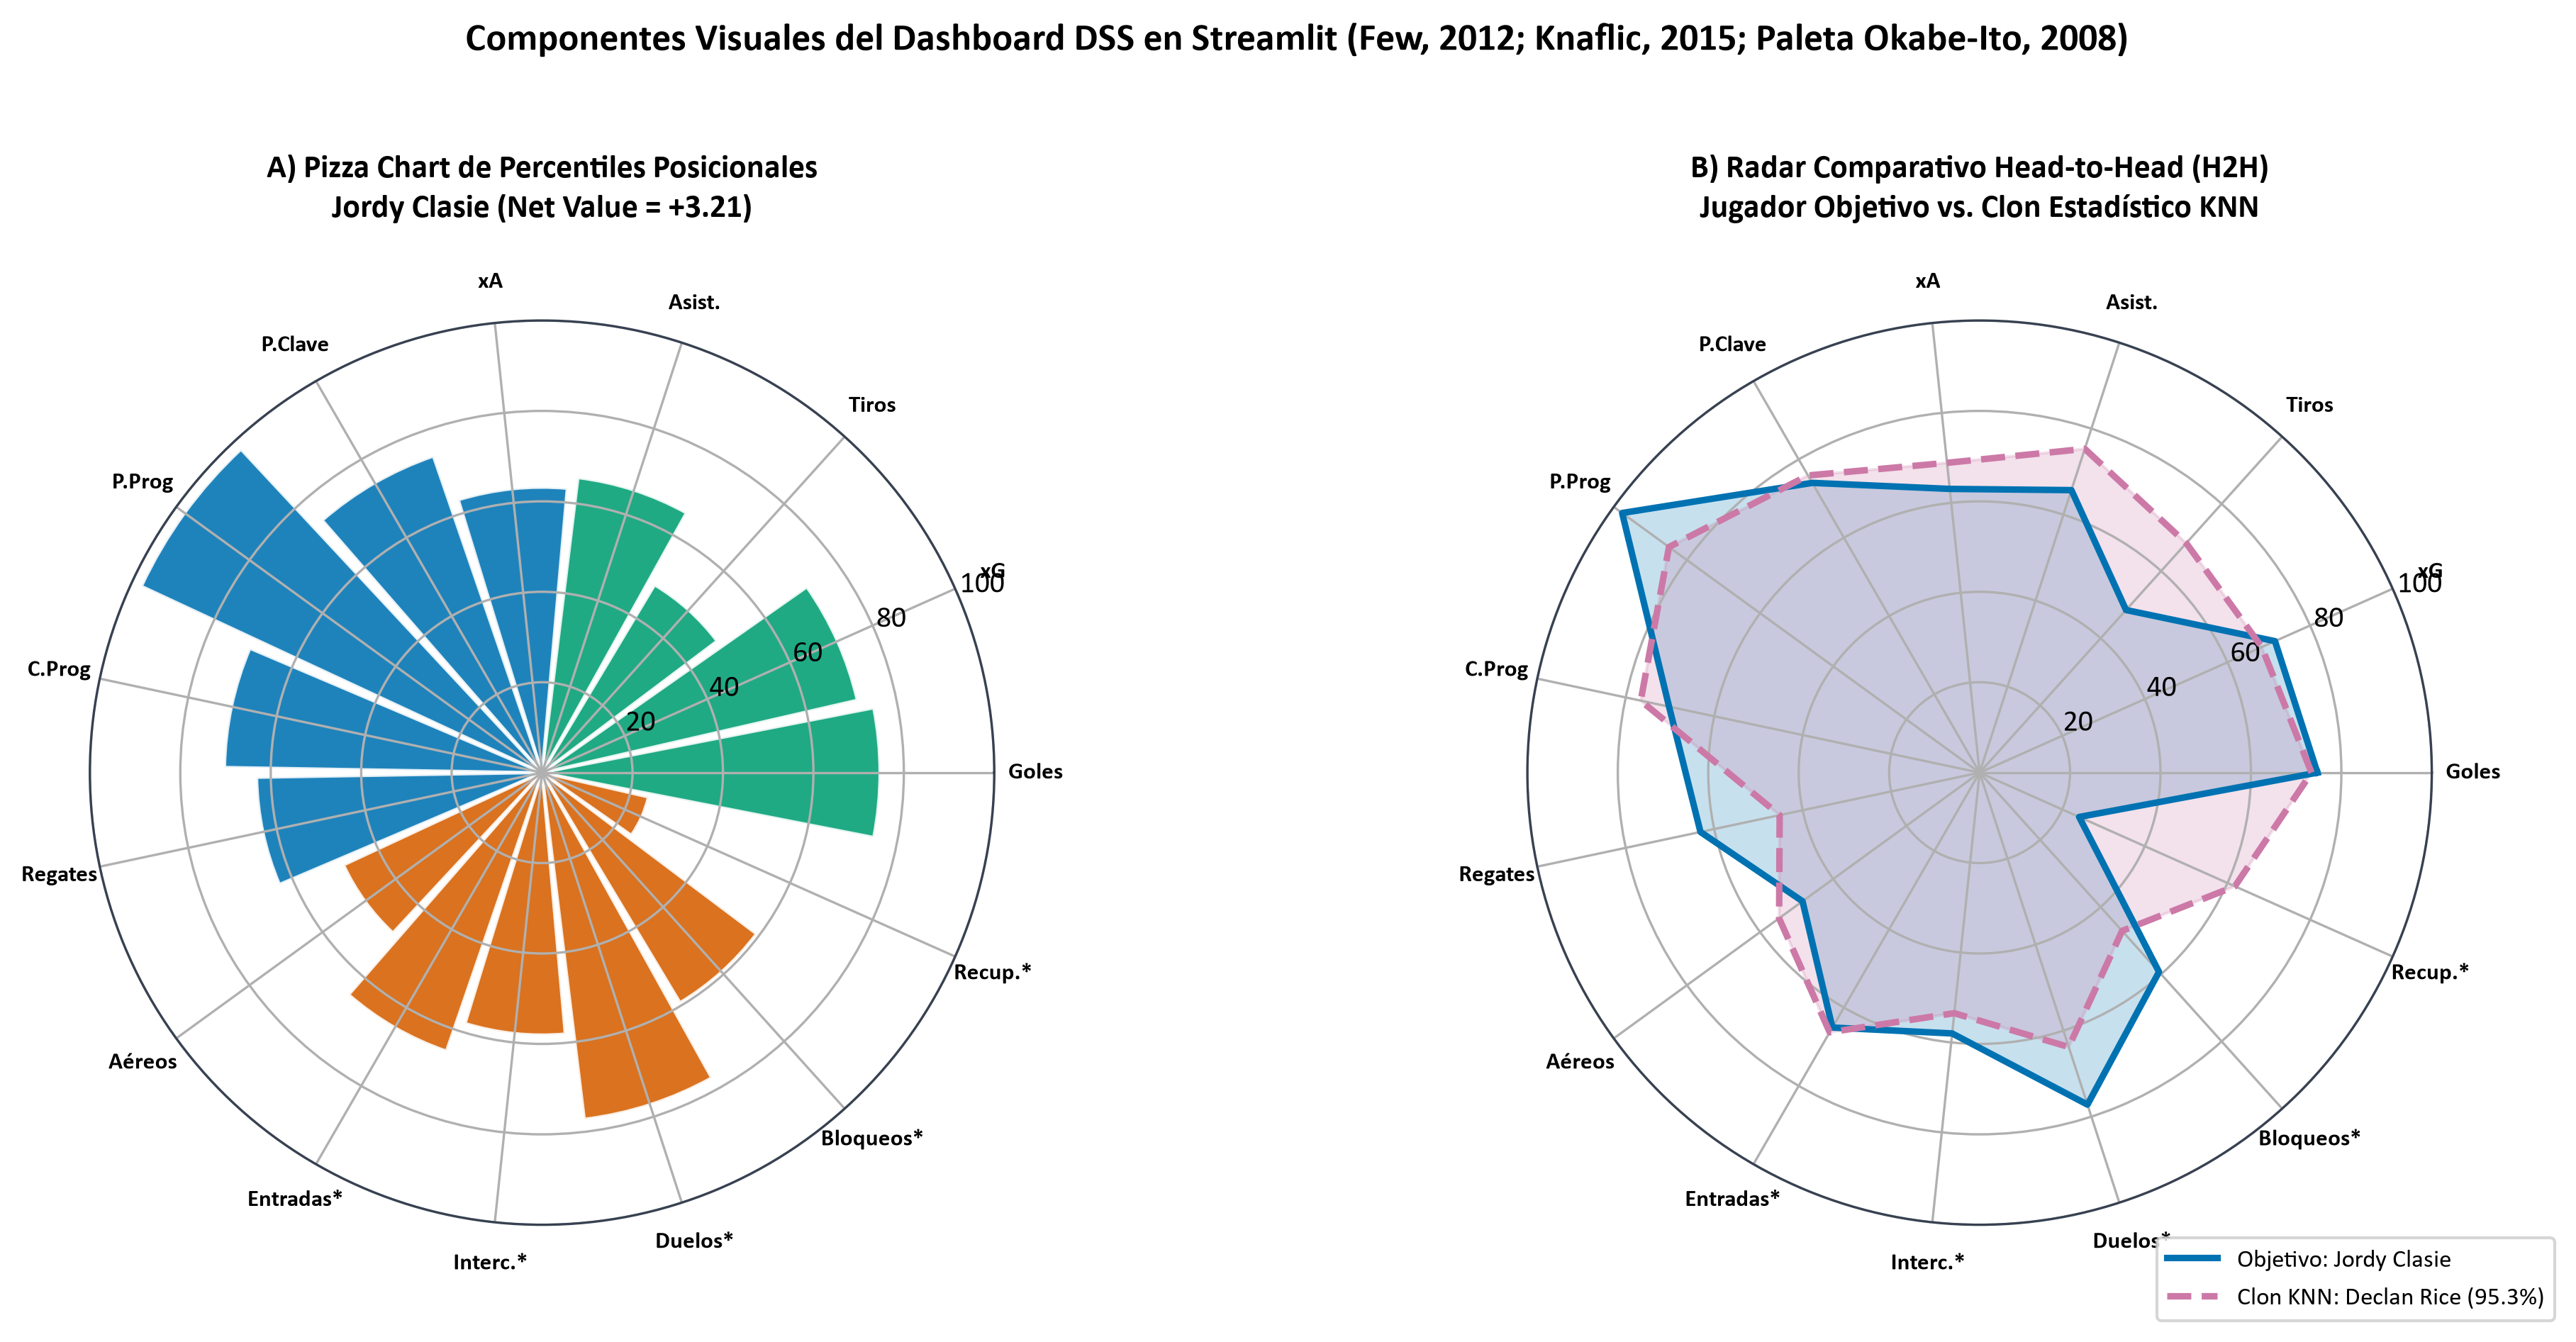

In [1]:
display(Image(filename='../docs/figures/fig15_dashboard_pizza_h2h_nba_scorecard.png'))